# Finite Element Analysis in Python: Trusses, Beams, Frames and Plates

A compact, readable finite element toolkit written with NumPy and SciPy only. Every solver is **validated against closed-form (analytical) results**, and every number, table and plot in this notebook is computed by the code below.

**Author:** Harpreet Singh

**Contents**
1. Introduction and workflow
2. Material properties
3. Truss solver (bar elements)
4. Euler-Bernoulli beam solver
5. Plane stress plate solver (Q4 element)
6. Mesh refinement and convergence
7. Validation against analytical solutions
8. Von Mises stress and safety factor
9. Modal (vibration) analysis
10. Portal frame (beam-column elements, static and modal)
11. 3D space truss
12. Summary

All units are SI (m, N, Pa, kg). `fea_core.py` must be in the same folder as this notebook.

## 1. Introduction and workflow

The finite element method splits a structure into small **elements** connected at **nodes**, writes the stiffness of each element as a matrix, and assembles them into one global system

$$\mathbf{K}\,\mathbf{u} = \mathbf{F}$$

where $\mathbf{K}$ is the global stiffness matrix, $\mathbf{u}$ the nodal displacements and $\mathbf{F}$ the nodal loads. Boundary conditions remove the rigid-body motion, the reduced system is solved, and stresses are recovered from the displacements.

**Workflow used in every section:** geometry, mesh, material, boundary conditions, load, solve, post-process, validate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from fea_core import (MATERIALS, Truss2D, Beam, Frame2D, Truss3D, PlaneStressQ4,
                      rect_mesh, quarter_hole_mesh, add_edge_load)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED, GREY = "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#7f7f7f"
RESULTS = {}   # collected numbers, used in the summary at the end
print("Setup complete")

Setup complete


## 2. Material properties

Typical handbook values at room temperature (always confirm with your own datasheet before real design work).

In [2]:
print(f"{'Material':<22}{'E [GPa]':>9}{'nu':>7}{'rho [kg/m3]':>13}{'yield [MPa]':>13}")
print("-" * 64)
for name, p in MATERIALS.items():
    print(f"{name:<22}{p['E']/1e9:>9.1f}{p['nu']:>7.3f}{p['rho']:>13.0f}{p['sy']/1e6:>13.0f}")

Material                E [GPa]     nu  rho [kg/m3]  yield [MPa]
----------------------------------------------------------------
Steel (structural)        210.0  0.300         7850          250
Aluminium 6061-T6          68.9  0.330         2700          276
Titanium Ti-6Al-4V        113.8  0.342         4430          880


## 3. Truss solver

A truss member carries only axial force. For a member with direction cosines $c=\cos\theta$, $s=\sin\theta$ the global stiffness is

$$\mathbf{k}=\frac{EA}{L}\begin{bmatrix} c^2 & cs & -c^2 & -cs\\ cs & s^2 & -cs & -s^2\\ -c^2 & -cs & c^2 & cs\\ -cs & -s^2 & cs & s^2\end{bmatrix}$$

**Check first:** a 3-member triangular truss that can be solved by hand with the method of joints.

In [3]:
E, A, P = 210e9, 1e-3, 10e3
tri = Truss2D([(0, 0), (4, 0), (2, 3)], [(0, 1), (0, 2), (1, 2)], E, A)
res = tri.solve({2: (0, -P)}, fixed=[(0, 0), (0, 1), (1, 1)])

N_exact = np.array([P / 3, -P * np.sqrt(13) / 6, -P * np.sqrt(13) / 6])
print(f"{'Member':<10}{'FEM [N]':>12}{'Exact [N]':>12}{'Error %':>10}")
for k, (n_fem, n_ex) in enumerate(zip(res["N"], N_exact)):
    print(f"{k:<10}{n_fem:>12.2f}{n_ex:>12.2f}{abs(n_fem-n_ex)/abs(n_ex)*100:>10.4f}")

Member         FEM [N]   Exact [N]   Error %
0              3333.33     3333.33    0.0000
1             -6009.25    -6009.25    0.0000
2             -6009.25    -6009.25    0.0000


**Warren bridge truss:** 5 bottom nodes and 4 top nodes, steel members of $20\ \mathrm{cm^2}$, a 20 kN load at each interior bottom node, pinned on the left and on a roller on the right.

In [4]:
bay, h = 3.0, 2.5
bottom = [(i * bay, 0.0) for i in range(5)]
top = [(bay / 2 + i * bay, h) for i in range(4)]
nodes = bottom + top
members = [(i, i + 1) for i in range(4)]                  # bottom chord
members += [(5 + i, 5 + i + 1) for i in range(3)]         # top chord
members += [(i, 5 + i) for i in range(4)]                 # diagonals up
members += [(5 + i, i + 1) for i in range(4)]             # diagonals down

bridge = Truss2D(nodes, members, 210e9, 20e-4)
loads = {1: (0, -20e3), 2: (0, -20e3), 3: (0, -20e3)}
sol = bridge.solve(loads, fixed=[(0, 0), (0, 1), (4, 1)])

Ry = sum(v for (nd, d), v in sol["reactions"].items() if d == 1)
print(f"Total vertical reaction: {Ry/1e3:.2f} kN  (applied load: 60.00 kN)")
imax = int(np.argmax(np.abs(sol["N"])))
print(f"Largest axial force: {sol['N'][imax]/1e3:.2f} kN in member {imax}")
print(f"Largest axial stress: {np.abs(sol['stress']).max()/1e6:.1f} MPa")
print(f"Maximum nodal displacement: {np.abs(sol['u']).max()*1e3:.2f} mm")
RESULTS["truss_Nmax_kN"] = float(sol["N"][imax] / 1e3)
RESULTS["truss_stress_MPa"] = float(np.abs(sol["stress"]).max() / 1e6)
RESULTS["truss_defl_mm"] = float(np.abs(sol["u"]).max() * 1e3)

Total vertical reaction: 60.00 kN  (applied load: 60.00 kN)
Largest axial force: -48.00 kN in member 5
Largest axial stress: 24.0 MPa
Maximum nodal displacement: 2.09 mm


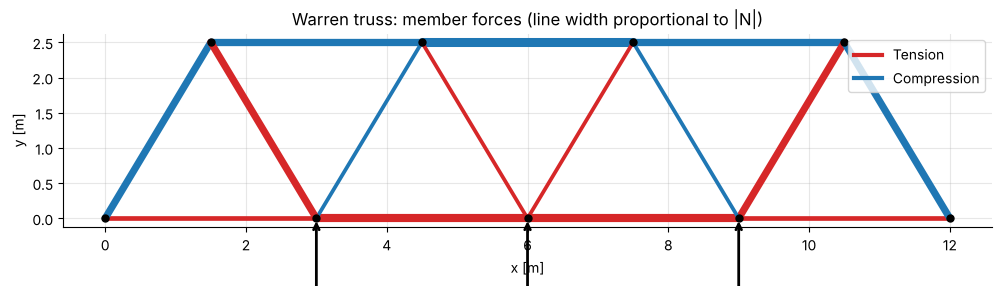

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6))
Nmax = np.abs(sol["N"]).max()
for k, (i, j) in enumerate(bridge.members):
    p = bridge.nodes[[i, j]]
    n = sol["N"][k]
    color = RED if n > 0 else BLUE          # red = tension, blue = compression
    ax.plot(p[:, 0], p[:, 1], color=color, lw=1.5 + 5 * abs(n) / Nmax, solid_capstyle="round")
ax.plot(bridge.nodes[:, 0], bridge.nodes[:, 1], "ko", ms=5)
ax.plot([], [], color=RED, lw=3, label="Tension")
ax.plot([], [], color=BLUE, lw=3, label="Compression")
for nd, (fx, fy) in loads.items():
    x, y = bridge.nodes[nd]
    ax.annotate("", xy=(x, y), xytext=(x, y - 1.0), arrowprops=dict(arrowstyle="->", color="k", lw=2))
ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Warren truss: member forces (line width proportional to |N|)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig("fig_truss_forces.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Euler-Bernoulli beam solver

Each element has two nodes with deflection $v$ and rotation $\theta$ at every node. The Hermite cubic element stiffness is

$$\mathbf{k}_e=\frac{EI}{L^3}\begin{bmatrix}12&6L&-12&6L\\6L&4L^2&-6L&2L^2\\-12&-6L&12&-6L\\6L&2L^2&-6L&4L^2\end{bmatrix}$$

A uniform load $q$ becomes the equivalent nodal vector $\frac{qL}{2}\,[1,\ L/6,\ 1,\ -L/6]^T$. Bending moment is positive when sagging and shear is $V=dM/dx$.

**Example 1: simply supported beam** with a 10 kN/m uniform load and a 20 kN point load at midspan.

In [6]:
E, I, L = 210e9, 8e-6, 4.0
w, Pm = 10e3, 20e3                     # N/m and N (downward)
nel = 8
ss = Beam(np.linspace(0, L, nel + 1), E, I)
mid = nel // 2
ss.solve(fixed=[0, 2 * nel], point_loads={mid: -Pm}, udl=-w)
x, v, V, M = ss.diagram()

v_exact = 5 * w * L**4 / (384 * E * I) + Pm * L**3 / (48 * E * I)
M_exact = w * L**2 / 8 + Pm * L / 4
print(f"Midspan deflection  FEM: {abs(v.min())*1e3:.4f} mm   exact: {v_exact*1e3:.4f} mm")
print(f"Maximum moment      FEM: {M.max()/1e3:.4f} kN.m  exact: {M_exact/1e3:.4f} kN.m")
R = ss.reactions()
print(f"Reactions: {R[0]/1e3:.2f} kN and {R[2*nel]/1e3:.2f} kN (total load {(w*L+Pm)/1e3:.2f} kN)")
RESULTS["ss_defl_mm"] = float(abs(v.min()) * 1e3)
RESULTS["ss_M_kNm"] = float(M.max() / 1e3)

Midspan deflection  FEM: 35.7143 mm   exact: 35.7143 mm
Maximum moment      FEM: 40.0000 kN.m  exact: 40.0000 kN.m
Reactions: 30.00 kN and 30.00 kN (total load 60.00 kN)


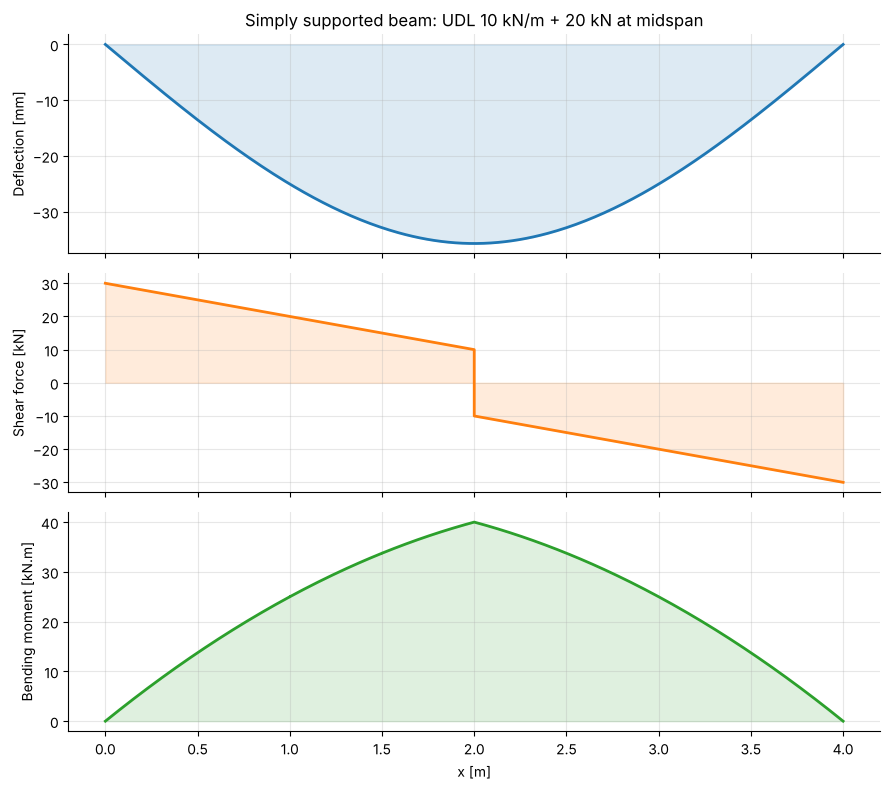

In [7]:
fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
axs[0].plot(x, v * 1e3, color=BLUE, lw=2); axs[0].fill_between(x, v * 1e3, 0, color=BLUE, alpha=0.15)
axs[0].set_ylabel("Deflection [mm]"); axs[0].set_title("Simply supported beam: UDL 10 kN/m + 20 kN at midspan")
axs[1].plot(x, V / 1e3, color=ORANGE, lw=2); axs[1].fill_between(x, V / 1e3, 0, color=ORANGE, alpha=0.15)
axs[1].set_ylabel("Shear force [kN]")
axs[2].plot(x, M / 1e3, color=GREEN, lw=2); axs[2].fill_between(x, M / 1e3, 0, color=GREEN, alpha=0.15)
axs[2].set_ylabel("Bending moment [kN.m]"); axs[2].set_xlabel("x [m]")
plt.tight_layout(); plt.savefig("fig_beam_diagrams.png", dpi=150, bbox_inches="tight"); plt.show()

**Example 2: cantilever beam** with a tip load. The deflected shape is compared with the exact curve $v(x)=\dfrac{P x^2}{6EI}(x-3L)$.

Tip deflection  FEM: -1.58730 mm   exact: -1.58730 mm
Wall moment     FEM: -2000.00 N.m   exact: -2000.00 N.m
Max difference between FEM and exact curve: 6.51e-19 m


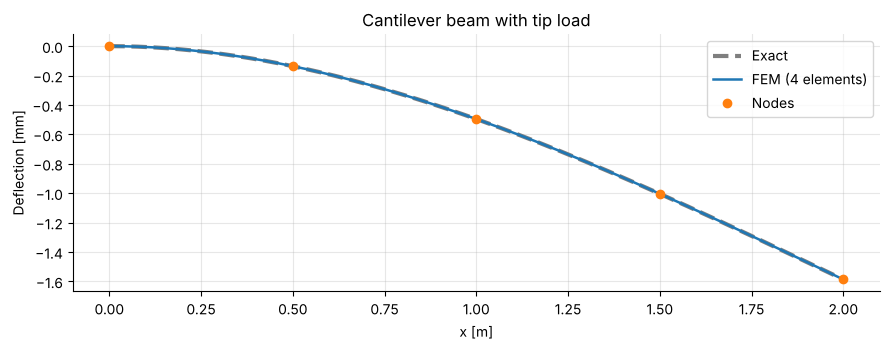

In [8]:
Lc, Pc = 2.0, 1000.0
cant = Beam(np.linspace(0, Lc, 5), E, I)
cant.solve(fixed=[0, 1], point_loads={4: -Pc})
xc, vc, Vc, Mc = cant.diagram()
v_ex = Pc * xc**2 / (6 * E * I) * (xc - 3 * Lc)

print(f"Tip deflection  FEM: {vc[-1]*1e3:.5f} mm   exact: {-Pc*Lc**3/(3*E*I)*1e3:.5f} mm")
print(f"Wall moment     FEM: {Mc[0]:.2f} N.m   exact: {-Pc*Lc:.2f} N.m")
print(f"Max difference between FEM and exact curve: {np.abs(vc - v_ex).max():.2e} m")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(xc, v_ex * 1e3, "--", color=GREY, lw=3, label="Exact")
ax.plot(xc, vc * 1e3, color=BLUE, lw=1.8, label="FEM (4 elements)")
ax.plot(cant.x, cant.u[0::2] * 1e3, "o", color=ORANGE, label="Nodes")
ax.set_xlabel("x [m]"); ax.set_ylabel("Deflection [mm]"); ax.set_title("Cantilever beam with tip load")
ax.legend(); plt.tight_layout(); plt.savefig("fig_cantilever.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Plane stress plate solver (Q4 element)

The 4-node quadrilateral uses bilinear shape functions, a $3\times 3$ strain-displacement matrix $\mathbf{B}$ and $2\times2$ Gauss integration:

$$\mathbf{k}_e=\int_{-1}^{1}\!\!\int_{-1}^{1}\mathbf{B}^T\mathbf{D}\,\mathbf{B}\;t\,\det\mathbf{J}\;d\xi\,d\eta,\qquad
\mathbf{D}=\frac{E}{1-\nu^2}\begin{bmatrix}1&\nu&0\\\nu&1&0\\0&0&\frac{1-\nu}{2}\end{bmatrix}$$

**Patch test:** a plate under uniform tension must give exactly constant stress $\sigma = F/A$ and elongation $\delta=\sigma L/E$.

In [9]:
E, nu, t = 210e9, 0.30, 0.01
Lx, Ly, s0 = 2.0, 1.0, 100e6
nodes, elems = rect_mesh(Lx, Ly, 4, 2)
plate = PlaneStressQ4(nodes, elems, E, nu, t)
F = np.zeros(plate.ndof)
right = np.where(np.isclose(nodes[:, 0], Lx))[0]
left = np.where(np.isclose(nodes[:, 0], 0))[0]
bottom_n = np.where(np.isclose(nodes[:, 1], 0))[0]
add_edge_load(F, nodes, right, 0, s0, t)
u = plate.solve(F, [2 * i for i in left] + [2 * i + 1 for i in bottom_n])
sig = plate.nodal_stress()
print(f"Stress sigma_x:  min {sig[:,0].min()/1e6:.6f} MPa, max {sig[:,0].max()/1e6:.6f} MPa (applied 100 MPa)")
print(f"Elongation  FEM: {u[2*right[0]]*1e3:.6f} mm   exact: {s0*Lx/E*1e3:.6f} mm")

Stress sigma_x:  min 100.000000 MPa, max 100.000000 MPa (applied 100 MPa)
Elongation  FEM: 0.952381 mm   exact: 0.952381 mm


**Plate with a circular hole.** Only one quarter is meshed, using symmetry conditions on the two cut edges. The plate is $1\,\mathrm{m}\times1\,\mathrm{m}$ with a hole of radius $a=50\,\mathrm{mm}$ and a nominal tension $\sigma_0 = 50\ \mathrm{MPa}$ in the x direction. The stress concentration factor is

$$K_t=\frac{\sigma_{x,\max}}{\sigma_0}$$

The classical Kirsch solution for a hole in an infinite plate gives $K_t = 3$. For finite width the handbook polynomial (Heywood/Peterson, net-section form) gives $K_t \approx 3.02$ here, with $d/W=0.1$.

In [10]:
E, nu, t = 210e9, 0.30, 0.01
a, Lq, s0 = 0.05, 0.5, 50e6            # hole radius, half plate size, nominal stress

def solve_hole(nr, nt, grade=2.0):
    nodes, elems = quarter_hole_mesh(a, Lq, nr, nt, grade)
    m = PlaneStressQ4(nodes, elems, E, nu, t)
    F = np.zeros(m.ndof)
    right = np.where(np.isclose(nodes[:, 0], Lq))[0]
    add_edge_load(F, nodes, right, 0, s0, t)
    sym_y = np.where(np.isclose(nodes[:, 1], 0))[0]       # y = 0 : uy = 0
    sym_x = np.where(np.isclose(nodes[:, 0], 0))[0]       # x = 0 : ux = 0
    m.solve(F, [2 * i + 1 for i in sym_y] + [2 * i for i in sym_x])
    return m, m.nodal_stress()

nr, nt = 24, 48
hole, sh = solve_hole(nr, nt)
top = nt * (nr + 1)                                        # node at x = 0, y = a (top of hole)
Kt = sh[top, 0] / s0
d_over_W = 2 * a / (2 * Lq)
Kt_peterson = (3.00 - 3.14 * d_over_W + 3.667 * d_over_W**2 - 1.527 * d_over_W**3) / (1 - d_over_W)
print(f"Mesh: {len(hole.nodes)} nodes, {len(hole.elems)} elements, {hole.ndof} dofs")
print(f"sigma_x at hole top: {sh[top,0]/1e6:.2f} MPa")
print(f"Kt  FEM: {Kt:.3f}   Kirsch (infinite plate): 3.000   Peterson (finite width): {Kt_peterson:.3f}")
RESULTS["Kt_fem"] = float(Kt); RESULTS["Kt_peterson"] = float(Kt_peterson)

Mesh: 1225 nodes, 1152 elements, 2450 dofs
sigma_x at hole top: 154.35 MPa
Kt  FEM: 3.087   Kirsch (infinite plate): 3.000   Peterson (finite width): 3.023


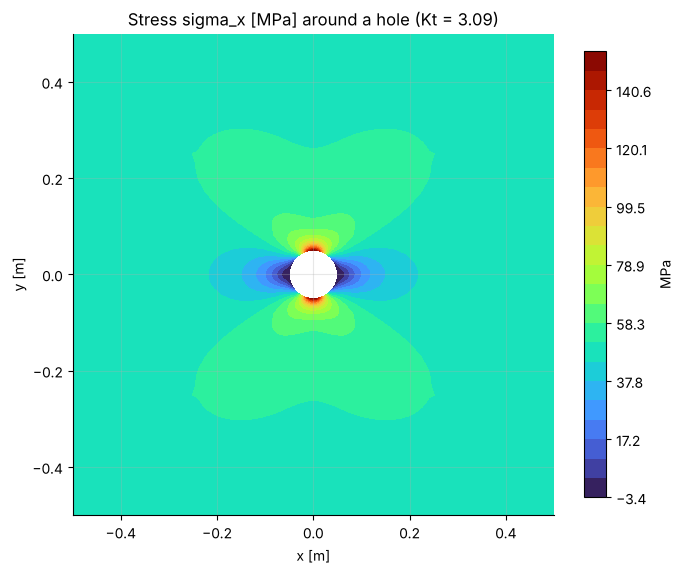

In [11]:
def mirrored_contour(ax, m, values, levels, cmap):
    tri_idx = np.vstack([m.elems[:, [0, 1, 2]], m.elems[:, [0, 2, 3]]])
    cs = None
    for sx, sy in [(1, 1), (-1, 1), (-1, -1), (1, -1)]:
        tr = mtri.Triangulation(sx * m.nodes[:, 0], sy * m.nodes[:, 1], tri_idx)
        cs = ax.tricontourf(tr, values, levels=levels, cmap=cmap)
    return cs

fig, ax = plt.subplots(figsize=(7, 6))
levels = np.linspace(sh[:, 0].min() / 1e6, sh[:, 0].max() / 1e6, 24)
cs = mirrored_contour(ax, hole, sh[:, 0] / 1e6, levels, "turbo")
ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title(f"Stress sigma_x [MPa] around a hole (Kt = {Kt:.2f})")
plt.colorbar(cs, ax=ax, shrink=0.85, label="MPa")
plt.tight_layout(); plt.savefig("fig_plate_contour.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Mesh refinement and convergence

A finite element answer should approach a fixed value as the mesh is refined. Two studies are shown:

* **Plate with a hole:** $K_t$ versus number of degrees of freedom.
* **Cantilever plate (Q4):** tip deflection against Euler-Bernoulli theory. The slender plate shows **shear locking** on coarse meshes, a known weakness of the fully integrated Q4 element, so coarse meshes are too stiff.

In [12]:
meshes = [(6, 8), (10, 16), (16, 32), (24, 48), (32, 64), (48, 96)]
dofs_h, kt_h = [], []
for nr_, nt_ in meshes:
    m_, s_ = solve_hole(nr_, nt_)
    dofs_h.append(m_.ndof); kt_h.append(s_[nt_ * (nr_ + 1), 0] / s0)

print(f"{'dofs':>8}{'Kt':>10}")
for d_, k_ in zip(dofs_h, kt_h):
    print(f"{d_:>8}{k_:>10.4f}")

Ec, nuc, tc, Lx, Ly, Pc = 210e9, 0.30, 0.1, 1.0, 0.2, 1000.0
Ic = tc * Ly**3 / 12
d_eb = Pc * Lx**3 / (3 * Ec * Ic)
d_tim = d_eb + Pc * Lx / ((5 / 6) * (Ec / (2 * (1 + nuc))) * tc * Ly)
cant_meshes = [(5, 1), (10, 2), (20, 4), (40, 8), (80, 16)]
dofs_c, ratio_eb, ratio_tim = [], [], []
for nx_, ny_ in cant_meshes:
    nd, el = rect_mesh(Lx, Ly, nx_, ny_)
    mc = PlaneStressQ4(nd, el, Ec, nuc, tc)
    Fc = np.zeros(mc.ndof)
    rt = np.where(np.isclose(nd[:, 0], Lx))[0]; lf = np.where(np.isclose(nd[:, 0], 0))[0]
    add_edge_load(Fc, nd, rt, 1, -Pc / (tc * Ly), tc)
    uc = mc.solve(Fc, [2 * i for i in lf] + [2 * i + 1 for i in lf])
    tip = -np.mean(uc[2 * rt + 1])
    dofs_c.append(mc.ndof); ratio_eb.append(tip / d_eb); ratio_tim.append(tip / d_tim)

print()
print(f"{'mesh':>8}{'dofs':>8}{'tip/EB':>10}{'tip/Timoshenko':>16}")
for (nx_, ny_), d_, r1, r2 in zip(cant_meshes, dofs_c, ratio_eb, ratio_tim):
    print(f"{nx_:>4}x{ny_:<3}{d_:>8}{r1:>10.4f}{r2:>16.4f}")
RESULTS["conv_kt_final"] = float(kt_h[-1]); RESULTS["conv_lock_coarse"] = float(ratio_eb[0])
RESULTS["conv_cant_fine_tim"] = float(ratio_tim[-1])

    dofs        Kt
     126    3.0363
     374    3.0778
    1122    3.0870
    2450    3.0869
    4290    3.0866
    9506    3.0864

    mesh    dofs    tip/EB  tip/Timoshenko
   5x1        24    0.6933          0.6724
  10x2        66    0.9104          0.8829
  20x4       210    0.9940          0.9640
  40x8       738    1.0185          0.9877
  80x16     2754    1.0251          0.9941


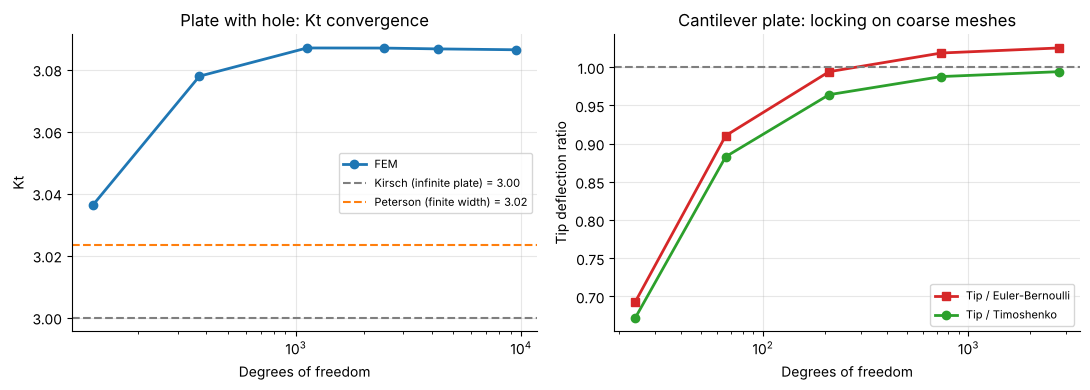

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].semilogx(dofs_h, kt_h, "o-", color=BLUE, lw=2, label="FEM")
axs[0].axhline(3.0, color=GREY, ls="--", label="Kirsch (infinite plate) = 3.00")
axs[0].axhline(Kt_peterson, color=ORANGE, ls="--", label=f"Peterson (finite width) = {Kt_peterson:.2f}")
axs[0].set_xlabel("Degrees of freedom"); axs[0].set_ylabel("Kt"); axs[0].set_title("Plate with hole: Kt convergence")
axs[0].legend(fontsize=8)
axs[1].semilogx(dofs_c, ratio_eb, "s-", color=RED, lw=2, label="Tip / Euler-Bernoulli")
axs[1].semilogx(dofs_c, ratio_tim, "o-", color=GREEN, lw=2, label="Tip / Timoshenko")
axs[1].axhline(1.0, color=GREY, ls="--")
axs[1].set_xlabel("Degrees of freedom"); axs[1].set_ylabel("Tip deflection ratio")
axs[1].set_title("Cantilever plate: locking on coarse meshes"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_convergence.png", dpi=150, bbox_inches="tight"); plt.show()

**Curing the locking: incompatible modes.** `PlaneStressQ4(..., incompatible=True)` adds two internal bubble modes, $1-\xi^2$ and $1-\eta^2$, to the displacement field (Wilson-Taylor). Their degrees of freedom are condensed out element by element, so the global system keeps the same size. The coarse 5x1 mesh now lands close to the Timoshenko answer instead of 67 % of it.

In [26]:
def cant_ratio(nx_, ny_, incompatible):
    nd, el = rect_mesh(Lx, Ly, nx_, ny_)
    mc = PlaneStressQ4(nd, el, Ec, nuc, tc, incompatible=incompatible)
    Fc = np.zeros(mc.ndof)
    rt = np.where(np.isclose(nd[:, 0], Lx))[0]; lf = np.where(np.isclose(nd[:, 0], 0))[0]
    add_edge_load(Fc, nd, rt, 1, -Pc / (tc * Ly), tc)
    uc = mc.solve(Fc, [2 * i for i in lf] + [2 * i + 1 for i in lf])
    return -np.mean(uc[2 * rt + 1]) / d_tim

std = [cant_ratio(nx_, ny_, False) for nx_, ny_ in cant_meshes]
inc = [cant_ratio(nx_, ny_, True) for nx_, ny_ in cant_meshes]
print(f"{'mesh':>8}{'dofs':>8}{'standard Q4':>14}{'with modes':>13}   (tip / Timoshenko)")
for (nx_, ny_), d_, a_, b_ in zip(cant_meshes, dofs_c, std, inc):
    print(f"{nx_:>4}x{ny_:<3}{d_:>8}{a_:>14.4f}{b_:>13.4f}")

RESULTS["lock_std_5x1"] = std[0]; RESULTS["lock_inc_5x1"] = inc[0]

    mesh    dofs   standard Q4   with modes   (tip / Timoshenko)
   5x1        24        0.6724       0.9853
  10x2        66        0.8829       0.9870
  20x4       210        0.9640       0.9929
  40x8       738        0.9877       0.9952
  80x16     2754        0.9941       0.9960


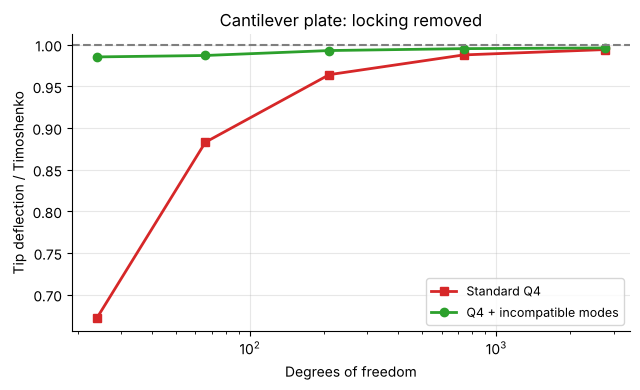

In [27]:
plt.figure(figsize=(6.5, 4))
plt.semilogx(dofs_c, std, "s-", color=RED, lw=2, label="Standard Q4")
plt.semilogx(dofs_c, inc, "o-", color=GREEN, lw=2, label="Q4 + incompatible modes")
plt.axhline(1.0, color=GREY, ls="--")
plt.xlabel("Degrees of freedom"); plt.ylabel("Tip deflection / Timoshenko")
plt.title("Cantilever plate: locking removed"); plt.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 7. Validation against analytical solutions

Five beam cases, the truss and the plate patch test, all compared with closed-form results.

Case                                  FEM [mm]  Exact [mm]   Error %
Cantilever, tip load                   1.58730     1.58730   0.00000
Cantilever, UDL                        1.19048     1.19048   0.00000
Simply supported, central load         0.09921     0.09921   0.00000
Simply supported, UDL                  0.12401     0.12401   0.00000
Fixed-fixed, UDL                       0.02480     0.02480   0.00000


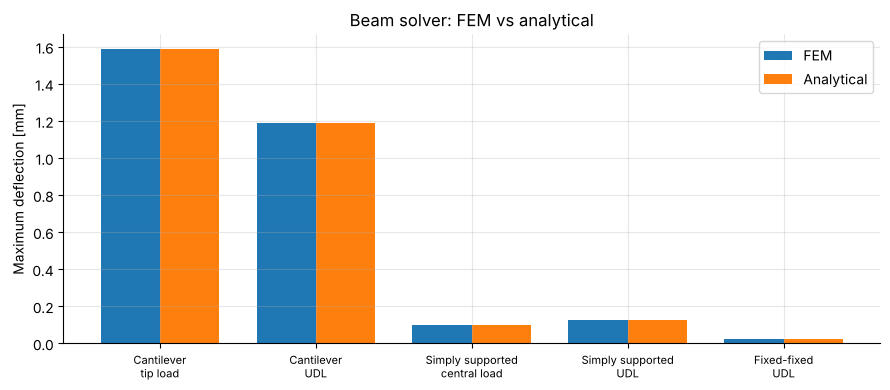

In [14]:
E, I, L, q, P = 210e9, 8e-6, 2.0, 1000.0, 1000.0
x5 = np.linspace(0, L, 5)

def tip_or_mid(beam, dof):
    return abs(beam.u[dof])

cases = []
b = Beam(x5, E, I); b.solve([0, 1], point_loads={4: -P})
cases.append(("Cantilever, tip load", tip_or_mid(b, 8), P * L**3 / (3 * E * I)))
b = Beam(x5, E, I); b.solve([0, 1], udl=-q)
cases.append(("Cantilever, UDL", tip_or_mid(b, 8), q * L**4 / (8 * E * I)))
b = Beam(x5, E, I); b.solve([0, 8], point_loads={2: -P})
cases.append(("Simply supported, central load", tip_or_mid(b, 4), P * L**3 / (48 * E * I)))
b = Beam(x5, E, I); b.solve([0, 8], udl=-q)
cases.append(("Simply supported, UDL", tip_or_mid(b, 4), 5 * q * L**4 / (384 * E * I)))
b = Beam(x5, E, I); b.solve([0, 1, 8, 9], udl=-q)
cases.append(("Fixed-fixed, UDL", tip_or_mid(b, 4), q * L**4 / (384 * E * I)))

print(f"{'Case':<34}{'FEM [mm]':>12}{'Exact [mm]':>12}{'Error %':>10}")
errs = []
for name, f_, e_ in cases:
    err = abs(f_ - e_) / e_ * 100
    errs.append(err)
    print(f"{name:<34}{f_*1e3:>12.5f}{e_*1e3:>12.5f}{err:>10.5f}")

fig, ax = plt.subplots(figsize=(9, 4))
xx = np.arange(len(cases)); wd = 0.38
ax.bar(xx - wd / 2, [c[1] * 1e3 for c in cases], wd, color=BLUE, label="FEM")
ax.bar(xx + wd / 2, [c[2] * 1e3 for c in cases], wd, color=ORANGE, label="Analytical")
ax.set_xticks(xx); ax.set_xticklabels([c[0].replace(", ", "\n") for c in cases], fontsize=8)
ax.set_ylabel("Maximum deflection [mm]"); ax.set_title("Beam solver: FEM vs analytical"); ax.legend()
plt.tight_layout(); plt.savefig("fig_fea_vs_analytical.png", dpi=150, bbox_inches="tight"); plt.show()
RESULTS["beam_max_err_pct"] = float(max(errs))

## 8. Von Mises stress and safety factor

For plane stress the equivalent stress is

$$\sigma_{vm}=\sqrt{\sigma_x^2-\sigma_x\sigma_y+\sigma_y^2+3\tau_{xy}^2}$$

and the safety factor against yielding is $SF=\sigma_y/\sigma_{vm,\max}$. Below, the plate with a hole is checked for the three materials at the same nominal stress, and the largest allowable nominal stress is found from $\sigma_{0,\max}=\sigma_y/K_t$.

Nominal stress: 50 MPa   max von Mises: 153.3 MPa   (Kt_vm = 3.07)

Material               Yield [MPa]  Safety factor  Max nominal [MPa]
--------------------------------------------------------------------
Steel (structural)             250           1.63               81.5
Aluminium 6061-T6              276           1.80               90.0
Titanium Ti-6Al-4V             880           5.74              287.0


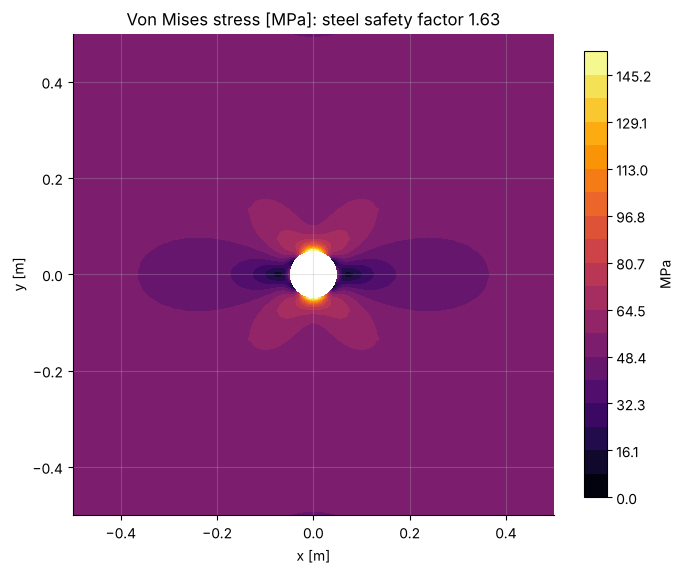

In [15]:
vm = PlaneStressQ4.von_mises(sh)
vm_max = vm.max()
print(f"Nominal stress: {s0/1e6:.0f} MPa   max von Mises: {vm_max/1e6:.1f} MPa   (Kt_vm = {vm_max/s0:.2f})")
print()
print(f"{'Material':<22}{'Yield [MPa]':>12}{'Safety factor':>15}{'Max nominal [MPa]':>19}")
print("-" * 68)
sf_all = {}
for name, p in MATERIALS.items():
    sf = p["sy"] / vm_max
    sf_all[name] = sf
    print(f"{name:<22}{p['sy']/1e6:>12.0f}{sf:>15.2f}{p['sy']/(vm_max/s0)/1e6:>19.1f}")
RESULTS["vm_max_MPa"] = float(vm_max / 1e6)
RESULTS["sf_steel"] = float(sf_all["Steel (structural)"])

fig, ax = plt.subplots(figsize=(7, 6))
lv = np.linspace(0, vm_max / 1e6, 20)
cs = mirrored_contour(ax, hole, vm / 1e6, lv, "inferno")
ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title(f"Von Mises stress [MPa]: steel safety factor {sf_all['Steel (structural)']:.2f}")
plt.colorbar(cs, ax=ax, shrink=0.85, label="MPa")
plt.tight_layout(); plt.savefig("fig_von_mises.png", dpi=150, bbox_inches="tight"); plt.show()

**Material comparison on a cantilever beam.** A 40 mm square beam, 1 m long, carries a 1 kN tip load. Stiffer materials deflect less, lighter materials weigh less, and the ratio $E/\rho$ (specific stiffness) tells which one is more efficient per kilogram.

Material               Tip defl [mm]  Mass [kg]  E/rho [MJ/kg]  Safety factor
-----------------------------------------------------------------------------
Steel (structural)             7.440      12.56          26.75           2.67
Aluminium 6061-T6             22.678       4.32          25.52           2.94
Titanium Ti-6Al-4V            13.730       7.09          25.69           9.39


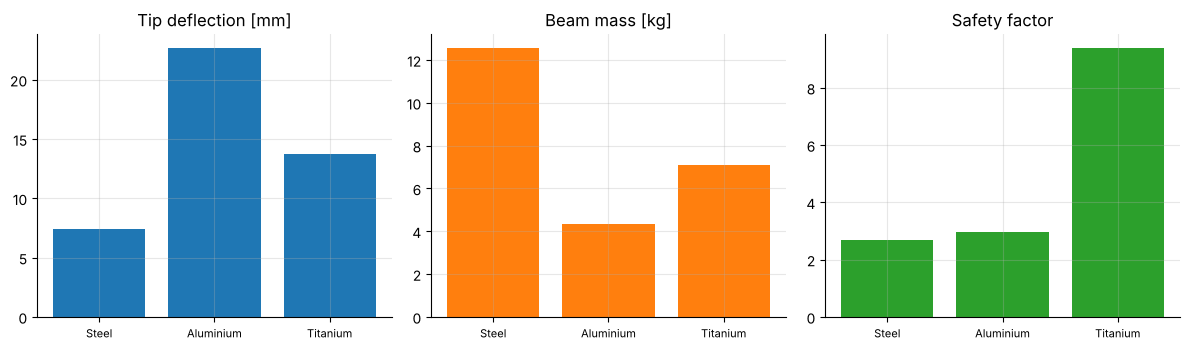

In [16]:
side, Lb, Pb = 0.04, 1.0, 1000.0
Ab, Ib = side**2, side**4 / 12
rows = []
for name, p in MATERIALS.items():
    bm_ = Beam(np.linspace(0, Lb, 11), p["E"], Ib)
    bm_.solve([0, 1], point_loads={10: -Pb})
    defl = abs(bm_.u[20]) * 1e3
    mass = p["rho"] * Ab * Lb
    sig = Pb * Lb * (side / 2) / Ib
    rows.append((name, defl, mass, p["E"] / p["rho"] / 1e6, p["sy"] / sig))

print(f"{'Material':<22}{'Tip defl [mm]':>14}{'Mass [kg]':>11}{'E/rho [MJ/kg]':>15}{'Safety factor':>15}")
print("-" * 77)
for r in rows:
    print(f"{r[0]:<22}{r[1]:>14.3f}{r[2]:>11.2f}{r[3]:>15.2f}{r[4]:>15.2f}")

fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
names = [r[0].split(" (")[0].split(" 6")[0].split(" Ti")[0] for r in rows]
for ax, idx, ttl, col in zip(axs, (1, 2, 4), ("Tip deflection [mm]", "Beam mass [kg]", "Safety factor"), (BLUE, ORANGE, GREEN)):
    ax.bar(names, [r[idx] for r in rows], color=col)
    ax.set_title(ttl); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.savefig("fig_materials.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Modal (vibration) analysis

Free vibration leads to the generalised eigenvalue problem

$$\mathbf{K}\,\boldsymbol{\phi}=\omega^2\,\mathbf{M}\,\boldsymbol{\phi}$$

with the consistent mass matrix of the beam element. For a cantilever the exact frequencies are

$$f_n=\frac{(\beta_nL)^2}{2\pi}\sqrt{\frac{EI}{\rho A L^4}},\qquad \beta_nL=1.8751,\ 4.6941,\ 7.8548,\ 10.9955$$

In [17]:
p = MATERIALS["Steel (structural)"]
side, Lm = 0.04, 1.0
Am, Im = side**2, side**4 / 12
mb = Beam(np.linspace(0, Lm, 21), p["E"], Im)
freqs, shapes = mb.modal(p["rho"], Am, fixed=[0, 1], nmodes=4)
bl = np.array([1.8751, 4.6941, 7.8548, 10.9955])
f_exact = bl**2 / (2 * np.pi) * np.sqrt(p["E"] * Im / (p["rho"] * Am * Lm**4))

print(f"{'Mode':<6}{'FEM [Hz]':>12}{'Exact [Hz]':>13}{'Error %':>10}")
for k in range(4):
    print(f"{k+1:<6}{freqs[k]:>12.3f}{f_exact[k]:>13.3f}{abs(freqs[k]-f_exact[k])/f_exact[k]*100:>10.4f}")
RESULTS["f1_fem"] = float(freqs[0]); RESULTS["f1_exact"] = float(f_exact[0])
RESULTS["modal_max_err_pct"] = float(np.max(np.abs(freqs - f_exact) / f_exact * 100))

Mode      FEM [Hz]   Exact [Hz]   Error %
1           33.421       33.421    0.0004
2          209.444      209.445    0.0002
3          586.458      586.455    0.0006
4         1149.277     1149.196    0.0070


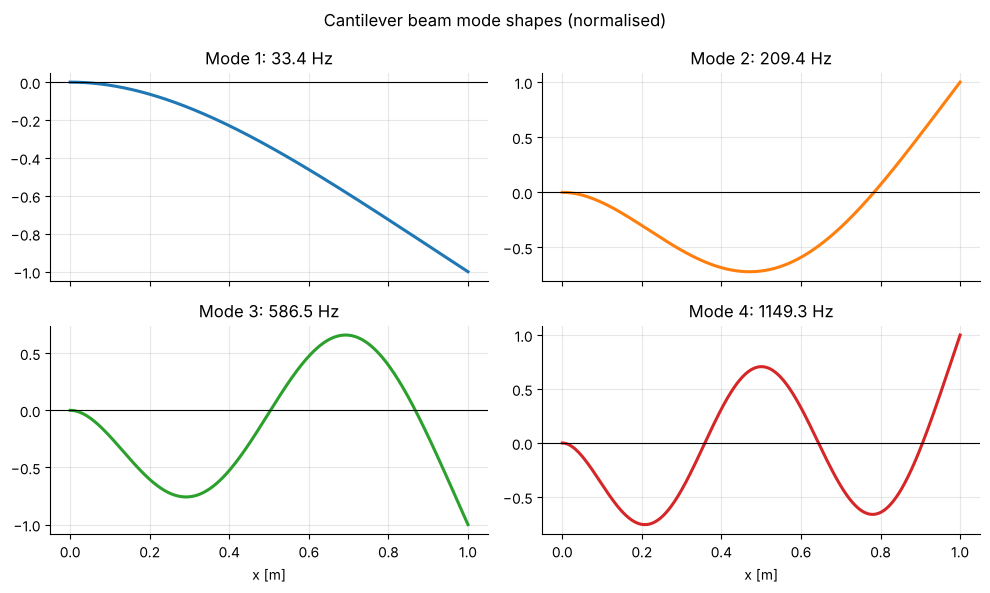

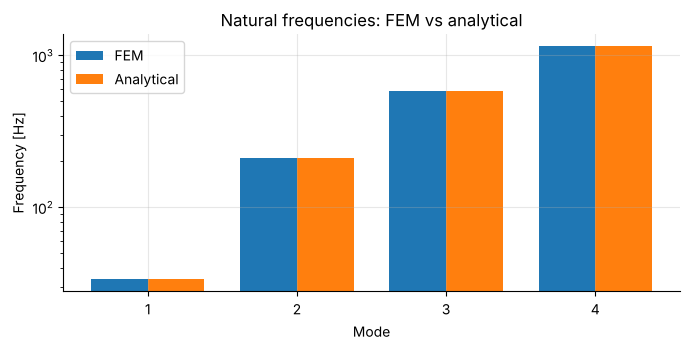

In [18]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for k, ax in enumerate(axs.ravel()):
    xs_, vs_ = mb.interp(shapes[:, k])
    ax.plot(xs_, vs_, lw=2.2, color=[BLUE, ORANGE, GREEN, RED][k])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"Mode {k+1}: {freqs[k]:.1f} Hz")
    if k >= 2: ax.set_xlabel("x [m]")
fig.suptitle("Cantilever beam mode shapes (normalised)")
plt.tight_layout(); plt.savefig("fig_mode_shapes.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.6))
xx = np.arange(1, 5); wd = 0.38
ax.bar(xx - wd / 2, freqs, wd, color=BLUE, label="FEM")
ax.bar(xx + wd / 2, f_exact, wd, color=ORANGE, label="Analytical")
ax.set_yscale("log"); ax.set_xticks(xx); ax.set_xlabel("Mode"); ax.set_ylabel("Frequency [Hz]")
ax.set_title("Natural frequencies: FEM vs analytical"); ax.legend()
plt.tight_layout(); plt.savefig("fig_frequencies.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Portal frame (beam-column elements)

`Frame2D` combines an axial bar with an Euler-Bernoulli beam, so each node has three dofs: $u_x$, $u_y$ and a rotation $\theta_z$. The local $6\times6$ stiffness matrix is rotated to global axes with $\mathbf{K}_e = \mathbf{T}^T \mathbf{k}_e \mathbf{T}$. A uniform load on a member is turned into fixed-end forces $wL/2$ and $\pm wL^2/12$, and subtracted again when the member end forces are recovered.

**Example:** a steel portal frame, 4 m span and 3 m high, fixed at both bases. A 10 kN lateral load acts at the left beam-column joint and a 5 kN/m uniform load acts on the beam.

In [20]:
E_f, A_f, I_f = 210e9, 7.7e-3, 1.0e-4          # steel section, A in m2, I in m4
span, height = 4.0, 3.0
nodes_f = [(0, 0), (0, height), (span, height), (span, 0)]
members_f = [(0, 1), (1, 2), (3, 2)]            # left column, beam, right column
frame = Frame2D(nodes_f, members_f, E_f, A_f, I_f)
fixed_f = [(0, 0), (0, 1), (0, 2), (3, 0), (3, 1), (3, 2)]
res_f = frame.solve(fixed_f, nodal_loads={1: (10e3, 0, 0)}, member_udl={1: -5e3})

Rx = sum(v for (n, d), v in res_f["reactions"].items() if d == 0)
Ry = sum(v for (n, d), v in res_f["reactions"].items() if d == 1)
print(f"Sway of joint 1       : {res_f['u'][1, 0]*1e3:.3f} mm")
print(f"Sum of reactions Rx,Ry: {Rx/1e3:.3f} kN, {Ry/1e3:.3f} kN")
print(f"Equilibrium check     : Rx + 10 kN = {(Rx+10e3):.2e} N, Ry - 5 kN/m*4 m = {(Ry-5e3*span):.2e} N")
RESULTS["frame_sway_mm"] = res_f["u"][1, 0] * 1e3
RESULTS["frame_equil_N"] = max(abs(Rx + 10e3), abs(Ry - 5e3 * span))

Sway of joint 1       : 0.841 mm
Sum of reactions Rx,Ry: -10.000 kN, 20.000 kN
Equilibrium check     : Rx + 10 kN = -3.64e-12 N, Ry - 5 kN/m*4 m = 0.00e+00 N


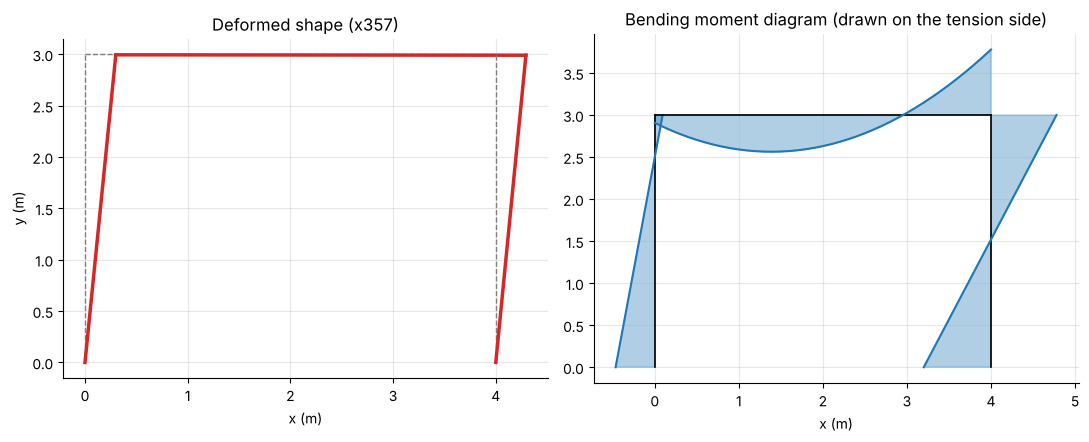

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
xy = np.array(nodes_f, float)
scale = 0.3 / np.abs(res_f["u"][:, :2]).max()
ax = axs[0]
for k, (i, j) in enumerate(members_f):
    ax.plot(*xy[[i, j]].T, "--", color=GREY, lw=1)
    ax.plot(*(xy[[i, j]] + scale * res_f["u"][[i, j], :2]).T, color=RED, lw=2.5)
ax.set_aspect("equal"); ax.set_title(f"Deformed shape (x{scale:.0f})")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")

ax = axs[1]
Mscale = 0.8 / max(np.abs(res_f["end_forces"][:, [2, 5]]).max(), 1.0)
wl = {1: -5e3}
for k, (i, j) in enumerate(members_f):
    _, _, Lk, c, s = frame.geometry(k)
    fe = res_f["end_forces"][k]
    sloc = np.linspace(0, Lk, 41)
    M = -fe[2] + fe[1] * sloc + wl.get(k, 0.0) * sloc**2 / 2     # sagging positive
    p = xy[i] + np.outer(sloc, [c, s])
    nrm = np.array([-s, c])
    ax.plot(*xy[[i, j]].T, color="k", lw=1.2)
    ax.fill(*np.vstack([p, (p + np.outer(-M, nrm) * Mscale)[::-1]]).T, color=BLUE, alpha=0.35)
    ax.plot(*(p - np.outer(M, nrm) * Mscale).T, color=BLUE, lw=1.5)
ax.set_aspect("equal"); ax.set_title("Bending moment diagram (drawn on the tension side)")
ax.set_xlabel("x (m)")
plt.tight_layout(); plt.show()

**Results.** The lateral load makes the frame sway, and the equilibrium check confirms that the reactions balance the applied loads (the residual is at round-off level). The moment diagram shows the usual portal-frame pattern: large moments at the joints and at the column bases.

**Natural frequencies of the portal frame.** With a consistent mass matrix $\mathbf{M}$ the free vibration problem is $\mathbf{K}\boldsymbol\phi = \omega^2 \mathbf{M}\boldsymbol\phi$, solved by `Frame2D.modal`. Because one beam element per member is too coarse for dynamics, each member is split into several elements, and the first frequency is checked for convergence.

In [22]:
def portal(nel, E=210e9, A=7.7e-3, I=1.0e-4, span=4.0, height=3.0):
    """Portal frame with nel elements per member. Returns (Frame2D, fixed dofs, node coordinates)."""
    pts = [(0.0, height * k / nel) for k in range(nel + 1)]                          # left column up
    pts += [(span * k / nel, height) for k in range(1, nel + 1)]                       # beam
    pts += [(span, height * (1 - k / nel)) for k in range(1, nel + 1)]                 # right column down
    conn = [(i, i + 1) for i in range(len(pts) - 1)]
    return Frame2D(pts, conn, E, A, I), [(0, 0), (0, 1), (0, 2), (len(pts) - 1, 0), (len(pts) - 1, 1), (len(pts) - 1, 2)], np.array(pts)

rho_s = 7850.0
print("elements/member   f1 [Hz]    f2 [Hz]    f3 [Hz]")
for nel in (1, 2, 4, 8, 16):
    fr_, fx_, _ = portal(nel)
    f_, _ = fr_.modal(rho_s, fx_, 3)
    print(f"{nel:>9}      {f_[0]:9.4f}  {f_[1]:9.4f}  {f_[2]:9.4f}")
fr_m, fx_m, pts_m = portal(16)
freqs_m, modes_m = fr_m.modal(rho_s, fx_m, 4)
RESULTS["frame_f1"] = freqs_m[0]
RESULTS["frame_f2"] = freqs_m[1]

elements/member   f1 [Hz]    f2 [Hz]    f3 [Hz]
        1        29.3893   106.2757   250.7687
        2        29.3468    85.1826   195.3859
        4        29.3407    84.5781   191.0859
        8        29.3397    84.5367   190.8208
       16        29.3395    84.5340   190.7978


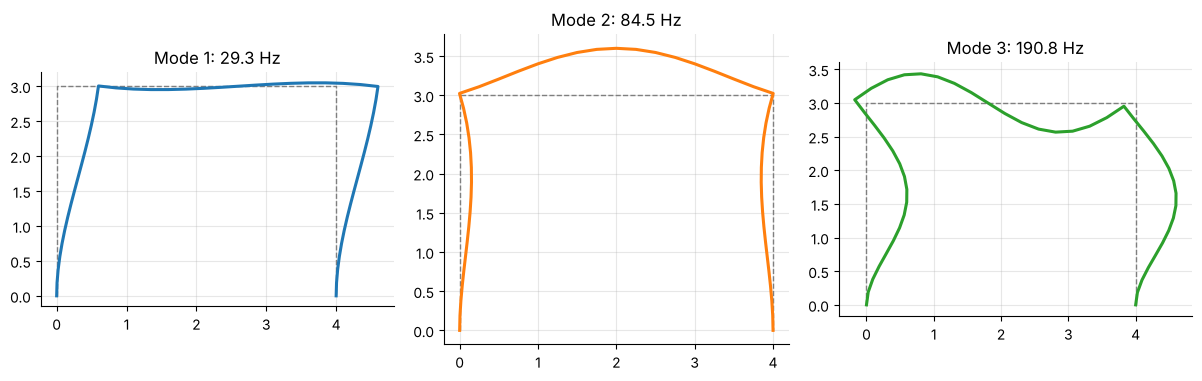

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for k, ax in enumerate(axs):
    phi = modes_m[:, k].reshape(-1, 3)[:, :2]
    phi = phi / np.abs(phi).max() * 0.6
    ax.plot(*pts_m.T, "--", color=GREY, lw=1)
    ax.plot(*(pts_m + phi).T, color=[BLUE, ORANGE, GREEN][k], lw=2.2)
    ax.set_aspect("equal"); ax.set_title(f"Mode {k+1}: {freqs_m[k]:.1f} Hz")
plt.tight_layout(); plt.show()

## 11. 3D space truss

`Truss3D` is the three-dimensional version of the bar element: each node has $u_x, u_y, u_z$ and the member stiffness is $\frac{EA}{L}\,\mathbf{c}\mathbf{c}^T$, where $\mathbf{c}$ is the unit vector along the member. Axial force is recovered from the elongation along $\mathbf{c}$.

**Example:** a small steel tower, 2 m x 2 m at the base and 1 m x 1 m at the top, 3 m high. It has four legs, a top ring and four face diagonals, with a 10 kN lateral and 20 kN downward load on one top node.

In [24]:
ang = np.array([[1, 1], [-1, 1], [-1, -1], [1, -1]], float)
base = np.c_[ang * 1.0, np.zeros(4)]                    # 2 m x 2 m at z = 0
top = np.c_[ang * 0.5, np.full(4, 3.0)]                  # 1 m x 1 m at z = 3 m
nodes3 = np.vstack([base, top])
legs = [(i, 4 + i) for i in range(4)]
ring = [(4 + i, 4 + (i + 1) % 4) for i in range(4)]
diag = [(i, 4 + (i + 1) % 4) for i in range(4)]
members3 = legs + ring + diag
tower = Truss3D(nodes3, members3, 210e9, 8e-4)
fixed3 = [(i, d) for i in range(4) for d in range(3)]
res3 = tower.solve({4: (10e3, 0, -20e3)}, fixed3)

Rx = sum(v for (n, d), v in res3["reactions"].items() if d == 0)
Rz = sum(v for (n, d), v in res3["reactions"].items() if d == 2)
print(f"Members: {len(members3)}, nodes: {len(nodes3)}")
print(f"Largest tension     : {res3['N'].max()/1e3:7.2f} kN")
print(f"Largest compression : {res3['N'].min()/1e3:7.2f} kN")
print(f"Top node displacement (ux, uy, uz): {np.round(res3['u'][4]*1e3, 3)} mm")
print(f"Equilibrium: Rx + 10 kN = {Rx + 10e3:.2e} N, Rz - 20 kN = {Rz - 20e3:.2e} N")
RESULTS["truss3d_Nmax_kN"] = np.abs(res3["N"]).max() / 1e3
RESULTS["truss3d_equil_N"] = max(abs(Rx + 10e3), abs(Rz - 20e3))

Members: 12, nodes: 8
Largest tension     :   10.27 kN
Largest compression :  -15.41 kN
Top node displacement (ux, uy, uz): [ 0.717  0.242 -0.131] mm
Equilibrium: Rx + 10 kN = 1.82e-12 N, Rz - 20 kN = -3.64e-12 N


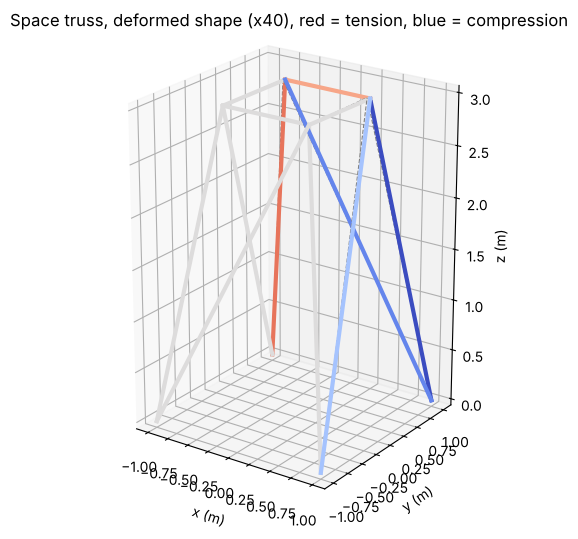

In [25]:
fig = plt.figure(figsize=(8, 5.5))
ax = fig.add_subplot(111, projection="3d")
Nm = np.abs(res3["N"]).max()
sc3 = 40.0
xyz_d = nodes3 + sc3 * res3["u"]
for k, (i, j) in enumerate(members3):
    col = plt.cm.coolwarm(0.5 + 0.5 * res3["N"][k] / Nm)      # red = tension, blue = compression
    ax.plot(*nodes3[[i, j]].T, "--", color=GREY, lw=0.8)
    ax.plot(*xyz_d[[i, j]].T, color=col, lw=3)
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("z (m)")
ax.set_title(f"Space truss, deformed shape (x{sc3:.0f}), red = tension, blue = compression")
ax.set_box_aspect((2, 2, 3)); ax.view_init(22, -55)
plt.tight_layout(); plt.show()

## 12. Summary

In [19]:
print("Key results (all computed in this notebook)")
print("-" * 60)
print(f"Beam solver, worst error over 5 cases       : {RESULTS['beam_max_err_pct']:.2e} %")
print(f"Warren truss, largest member force          : {RESULTS['truss_Nmax_kN']:.2f} kN")
print(f"Warren truss, largest axial stress          : {RESULTS['truss_stress_MPa']:.1f} MPa")
print(f"Plate with hole, Kt (FEM / Peterson)        : {RESULTS['Kt_fem']:.3f} / {RESULTS['Kt_peterson']:.3f}")
print(f"Plate with hole, finest-mesh Kt             : {RESULTS['conv_kt_final']:.3f}")
print(f"Cantilever plate, coarse mesh locking ratio : {RESULTS['conv_lock_coarse']:.3f}")
print(f"Steel safety factor at 50 MPa nominal       : {RESULTS['sf_steel']:.2f}")
print(f"Cantilever mode 1 (FEM / exact)             : {RESULTS['f1_fem']:.2f} / {RESULTS['f1_exact']:.2f} Hz")
print(f"Modal analysis, worst error over 4 modes    : {RESULTS['modal_max_err_pct']:.4f} %")
print(f"Portal frame sway, equilibrium residual  : {RESULTS['frame_sway_mm']:.3f} mm, {RESULTS['frame_equil_N']:.1e} N")
print(f"Portal frame, first two frequencies         : {RESULTS['frame_f1']:.2f} / {RESULTS['frame_f2']:.2f} Hz")
print(f"3D tower, largest member force              : {RESULTS['truss3d_Nmax_kN']:.2f} kN (equilibrium residual {RESULTS['truss3d_equil_N']:.1e} N)")
print(f"Cantilever plate 5x1 mesh, tip/Timoshenko   : {RESULTS['lock_std_5x1']:.3f} standard, {RESULTS['lock_inc_5x1']:.3f} with incompatible modes")

Key results (all computed in this notebook)
------------------------------------------------------------
Beam solver, worst error over 5 cases       : 9.56e-14 %
Warren truss, largest member force          : -48.00 kN
Warren truss, largest axial stress          : 24.0 MPa
Plate with hole, Kt (FEM / Peterson)        : 3.087 / 3.023
Plate with hole, finest-mesh Kt             : 3.086
Cantilever plate, coarse mesh locking ratio : 0.693
Steel safety factor at 50 MPa nominal       : 1.63
Cantilever mode 1 (FEM / exact)             : 33.42 / 33.42 Hz
Modal analysis, worst error over 4 modes    : 0.0070 %
Portal frame sway, equilibrium residual  : 0.841 mm, 3.6e-12 N
Portal frame, first two frequencies         : 29.34 / 84.53 Hz
3D tower, largest member force              : 15.41 kN (equilibrium residual 3.6e-12 N)
Cantilever plate 5x1 mesh, tip/Timoshenko   : 0.672 standard, 0.985 with incompatible modes


**What this shows**

* The beam and truss solvers reproduce textbook results to machine precision, because Hermite beam elements and bar elements are exact for these load cases.
* The Q4 plate element is exact for a uniform stress state, converges for the stress concentration, but locks on coarse meshes of slender bending problems. Refine the mesh or use reduced integration or enhanced-strain elements for such cases.
* The finite-width $K_t$ differs slightly from the long-strip handbook value because the model is a square plate, not an infinitely long strip.

**Limitations:** linear elasticity, small deformations, static or free-vibration analysis only. Results are for learning and prototyping, not a substitute for a certified design check.